In [ ]:
from sklearn.datasets import load_diabetes
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
diabetes = load_diabetes(as_frame=True, scaled=False)

df = diabetes.frame

df.to_csv('diabetes.csv', index=False)

In [ ]:
print(df.head())
print(df.shape)

    age  sex   bmi     bp     s1     s2    s3   s4      s5    s6  target
0  59.0  2.0  32.1  101.0  157.0   93.2  38.0  4.0  4.8598  87.0   151.0
1  48.0  1.0  21.6   87.0  183.0  103.2  70.0  3.0  3.8918  69.0    75.0
2  72.0  2.0  30.5   93.0  156.0   93.6  41.0  4.0  4.6728  85.0   141.0
3  24.0  1.0  25.3   84.0  198.0  131.4  40.0  5.0  4.8903  89.0   206.0
4  50.0  1.0  23.0  101.0  192.0  125.4  52.0  4.0  4.2905  80.0   135.0
(442, 11)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [ ]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000
mean,48.518100,1.468326,26.375792,94.647014,189.140271,115.439140,49.788462,4.070249,4.641411,91.260181,152.133484
std,13.109028,0.499561,4.418122,13.831283,34.608052,30.413081,12.934202,1.290450,0.522391,11.496335,77.093005
min,19.000000,1.000000,18.000000,62.000000,97.000000,41.600000,22.000000,2.000000,3.258100,58.000000,25.000000
25%,38.250000,1.000000,23.200000,84.000000,164.250000,96.050000,40.250000,3.000000,4.276700,83.250000,87.000000
50%,50.000000,1.000000,25.700000,93.000000,186.000000,113.000000,48.000000,4.000000,4.620050,91.000000,140.500000
75%,59.000000,2.000000,29.275000,105.000000,209.750000,134.500000,57.750000,5.000000,4.997200,98.000000,211.500000
max,79.000000,2.000000,42.200000,133.000000,301.000000,242.400000,99.000000,9.090000,6.107000,124.000000,346.000000


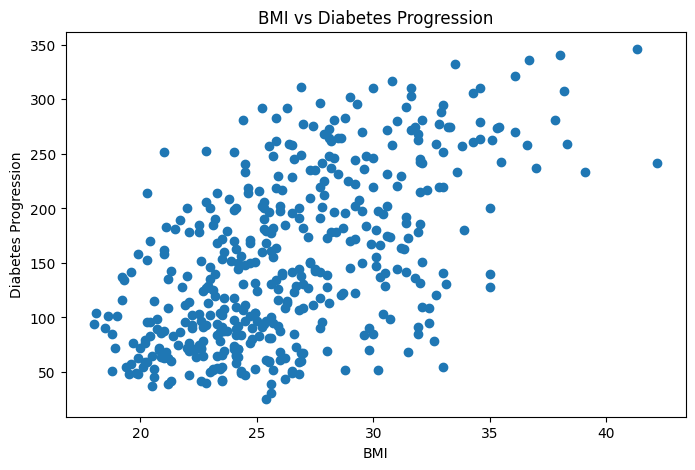

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(df['bmi'], df['target'])

plt.xlabel('BMI')
plt.ylabel('Diabetes Progression')
plt.title('BMI vs Diabetes Progression')

plt.show()

In [ ]:
correlation = df['bmi'].corr(df['target'])

print(correlation)

0.5864501344746885


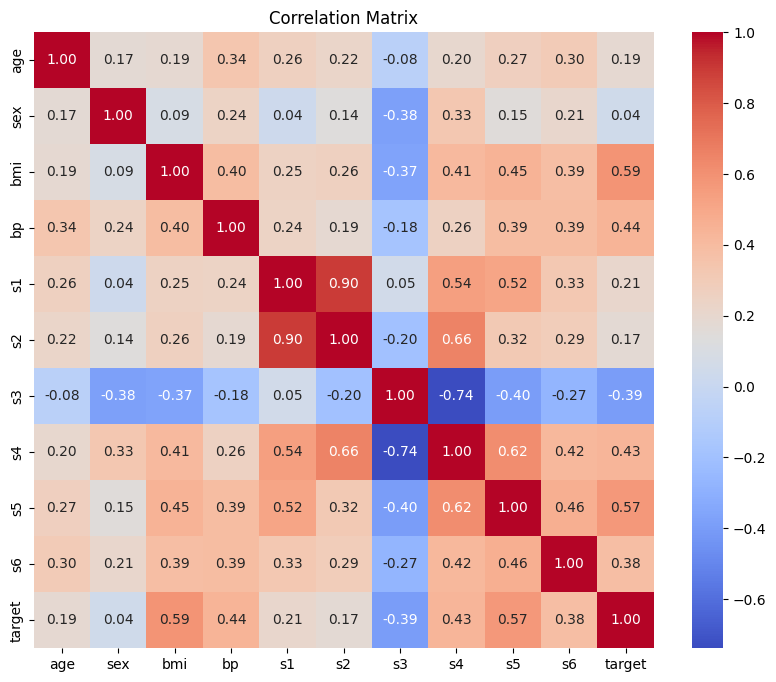

In [ ]:
correlation_matrix = df.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Matrix')

plt.show()

In [ ]:
target_correlation = df.corr()['target']

target_correlation = target_correlation.drop('target')

target_correlation = target_correlation.sort_values(
    ascending=False,
    key=abs
)

print(target_correlation)

bmi    0.586450
s5     0.565883
bp     0.441482
s4     0.430453
s3    -0.394789
s6     0.382483
s1     0.212022
age    0.187889
s2     0.174054
sex    0.043062
Name: target, dtype: float64


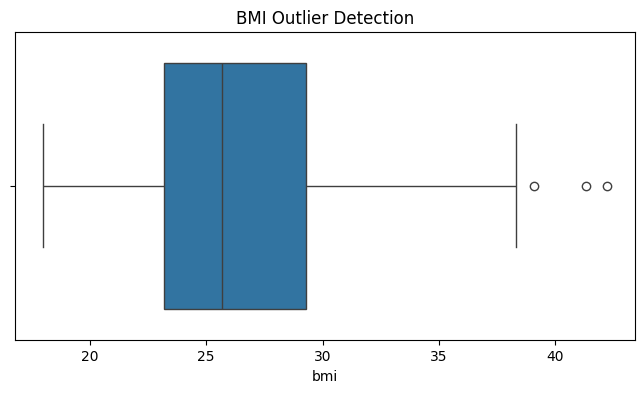

In [ ]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df['bmi'])

plt.title('BMI Outlier Detection')

plt.show()

In [ ]:
Q1 = df['bmi'].quantile(0.25)

Q3 = df['bmi'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)

upper_bound = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 23.2
Q3: 29.275
IQR: 6.074999999999999
Lower Bound: 14.0875
Upper Bound: 38.387499999999996


In [ ]:
outliers = df[
    (df['bmi'] < lower_bound) |
    (df['bmi'] > upper_bound)
]

print(outliers[['bmi', 'target']])

      bmi  target
256  41.3   346.0
366  39.1   233.0
367  42.2   242.0


In [ ]:
columns = df.columns.drop('sex')

for column in columns:

    Q1 = df[column].quantile(0.25)

    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)

    upper_bound = Q3 + (1.5 * IQR)

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(column, ":", len(outliers))

age : 0
bmi : 3
bp : 0
s1 : 8
s2 : 7
s3 : 7
s4 : 2
s5 : 4
s6 : 9
target : 0


In [ ]:
X = df.drop('target', axis=1)

y = df['target']

print("X shape:", X.shape)

print("y shape:", y.shape)

X shape: (442, 10)
y shape: (442,)


In [ ]:
X_simple = df[['bmi']]

y = df['target']

print(X_simple.shape)
print(y.shape)

(442, 1)
(442,)


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X_simple,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (353, 1)
X_test: (89, 1)
y_train: (353,)
y_test: (89,)


In [ ]:
from sklearn.linear_model import LinearRegression
model_simple = LinearRegression()

In [ ]:
model_simple.fit(X_train, y_train)

LinearRegression()

In [ ]:
print("Slope:", model_simple.coef_)
print("Intercept:", model_simple.intercept_)

Slope: [10.7627909]
Intercept: -131.87377836094223


In [ ]:
y_pred = model_simple.predict(X_test)
print(y_pred[:10])
print(y_test.head(10))

[145.80622687 188.85739048 147.95878505 203.92529774 131.8145987
 127.50948234 322.31599764 197.4676232   61.85645785 167.33180868]
287    219.0
211     70.0
72     202.0
321    230.0
73     111.0
418     84.0
367    242.0
354    272.0
281     94.0
148     96.0
Name: target, dtype: float64


In [ ]:
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

print(comparison.head(10))

     Actual   Predicted
287   219.0  145.806227
211    70.0  188.857390
72    202.0  147.958785
321   230.0  203.925298
73    111.0  131.814599
418    84.0  127.509482
367   242.0  322.315998
354   272.0  197.467623
281    94.0   61.856458
148    96.0  167.331809


In [ ]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 52.259976445345536


In [ ]:
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, y_pred)

print("MSE:", mse)

MSE: 4061.8259284949268


In [ ]:
from sklearn.metrics import root_mean_squared_error
rmse = root_mean_squared_error(y_test, y_pred)

print("RMSE:", rmse)

RMSE: 63.73245584860925


In [ ]:
from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.23335039815872138


The Simple Linear Regression model achieved an R² score of approximately 0.233, indicating that BMI alone explains about 23.3% of the variation in disease progression. This suggests that additional features may be needed to improve predictive performance.

In [ ]:
X = df.drop('target', axis=1)
y = df['target']
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("X_train_multi:", X_train_multi.shape)
print("X_test_multi:", X_test_multi.shape)

X_train_multi: (353, 10)
X_test_multi: (89, 10)


In [ ]:
model_multiple = LinearRegression()
model_multiple.fit(X_train_multi, y_train_multi)
print("Intercept:", model_multiple.intercept_)
print("Coefficients:", model_multiple.coef_)
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model_multiple.coef_
})

print(coefficients)

Intercept: -341.3782363335064
Coefficients: [  0.13768782 -23.06446772   5.84636265   1.19709252  -1.28168474
   0.81115203   0.60165319  10.15953917  67.1089624    0.20159907]
  Feature  Coefficient
0     age     0.137688
1     sex   -23.064468
2     bmi     5.846363
3      bp     1.197093
4      s1    -1.281685
5      s2     0.811152
6      s3     0.601653
7      s4    10.159539
8      s5    67.108962
9      s6     0.201599


In [ ]:
y_pred_multi = model_multiple.predict(X_test_multi)
print(y_pred_multi[:10])
print(y_test_multi.head(10))

[139.5475584  179.51720835 134.03875572 291.41702925 123.78965872
  92.1723465  258.23238899 181.33732057  90.22411311 108.63375858]
287    219.0
211     70.0
72     202.0
321    230.0
73     111.0
418     84.0
367    242.0
354    272.0
281     94.0
148     96.0
Name: target, dtype: float64


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_multi = mean_absolute_error(y_test_multi, y_pred_multi)
mse_multi = mean_squared_error(y_test_multi, y_pred_multi)
rmse_multi = np.sqrt(mse_multi)
r2_multi = r2_score(y_test_multi, y_pred_multi)

print("MAE:", mae_multi)
print("MSE:", mse_multi)
print("RMSE:", rmse_multi)
print("R2 Score:", r2_multi)

MAE: 42.79409467959994
MSE: 2900.193628493481
RMSE: 53.85344583676592
R2 Score: 0.4526027629719196


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)
print(X_train_poly[:5])
print(X_train_poly.shape)

[[ 27.5  756.25]
 [ 24.7  610.09]
 [ 31.   961.  ]
 [ 23.1  533.61]
 [ 20.3  412.09]]
(353, 2)


In [ ]:
model_poly = LinearRegression()

model_poly.fit(X_train_poly, y_train)
print("Intercept:", model_poly.intercept_)
print("Coefficients:", model_poly.coef_)

Intercept: -65.26897410626097
Coefficients: [5.83606965 0.08865889]


In [ ]:
y_pred_poly = model_poly.predict(X_test_poly)

print(y_pred_poly[:10])
print(y_test.head(10))

[144.31652431 187.37853935 146.40224431 203.1205058  130.93222915
 126.87427253 338.90045722 196.33139248  68.50575893 165.49289628]
287    219.0
211     70.0
72     202.0
321    230.0
73     111.0
418     84.0
367    242.0
354    272.0
281     94.0
148     96.0
Name: target, dtype: float64


In [ ]:
mae_poly = mean_absolute_error(y_test, y_pred_poly)
mse_poly = mean_squared_error(y_test, y_pred_poly)
rmse_poly = np.sqrt(mse_poly)
r2_poly = r2_score(y_test, y_pred_poly)

print("MAE:", mae_poly)
print("MSE:", mse_poly)
print("RMSE:", rmse_poly)
print("R2 Score:", r2_poly)

MAE: 52.383911760152635
MSE: 4085.025480871631
RMSE: 63.91420406194253
R2 Score: 0.22897159712056692


In [ ]:
mae_simple = mean_absolute_error(y_test, y_pred)
mse_simple = mean_squared_error(y_test, y_pred)
rmse_simple = np.sqrt(mse_simple)
r2_simple = r2_score(y_test, y_pred)

In [ ]:
results = pd.DataFrame({
    'Model': [
        'Simple Linear Regression',
        'Multiple Linear Regression',
        'Polynomial Regression'
    ],
    'MAE': [mae_simple, mae_multi, mae_poly],
    'MSE': [mse_simple, mse_multi, mse_poly],
    'RMSE': [rmse_simple, rmse_multi, rmse_poly],
    'R2 Score': [r2_simple, r2_multi, r2_poly]
})

print(results)

                        Model        MAE          MSE       RMSE  R2 Score
0    Simple Linear Regression  52.259976  4061.825928  63.732456  0.233350
1  Multiple Linear Regression  42.794095  2900.193628  53.853446  0.452603
2       Polynomial Regression  52.383912  4085.025481  63.914204  0.228972


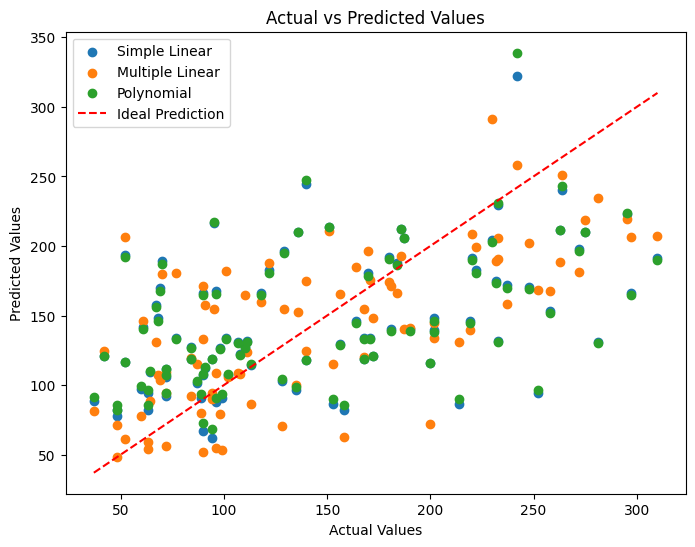

In [ ]:
plt.figure(figsize=(8, 6))

# Plot predictions
plt.scatter(y_test, y_pred, label='Simple Linear')
plt.scatter(y_test_multi, y_pred_multi, label='Multiple Linear')
plt.scatter(y_test, y_pred_poly, label='Polynomial')

# Ideal prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--',
    label='Ideal Prediction'
)

plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values')
plt.legend()
plt.show()

In [ ]:
residuals_simple = y_test - y_pred

residuals_multi = y_test_multi - y_pred_multi

residuals_poly = y_test - y_pred_poly

print("Simple Residuals:")
print(residuals_simple.head())

print("\nMultiple Residuals:")
print(residuals_multi.head())

print("\nPolynomial Residuals:")
print(residuals_poly.head())

Simple Residuals:
287     73.193773
211   -118.857390
72      54.041215
321     26.074702
73     -20.814599
Name: target, dtype: float64

Multiple Residuals:
287     79.452442
211   -109.517208
72      67.961244
321    -61.417029
73     -12.789659
Name: target, dtype: float64

Polynomial Residuals:
287     74.683476
211   -117.378539
72      55.597756
321     26.879494
73     -19.932229
Name: target, dtype: float64


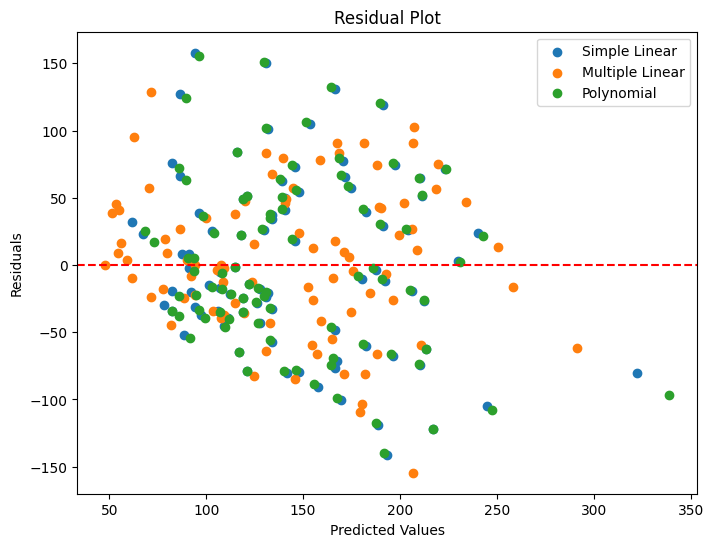

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals_simple, label='Simple Linear')
plt.scatter(y_pred_multi, residuals_multi, label='Multiple Linear')
plt.scatter(y_pred_poly, residuals_poly, label='Polynomial')

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.legend()
plt.show()

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

poly_multi = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly_multi = poly_multi.fit_transform(X_train_multi)

X_test_poly_multi = poly_multi.transform(X_test_multi)

print("Original Features:", X_train_multi.shape)

print("Polynomial Features:", X_train_poly_multi.shape)

print("Test Features:", X_test_poly_multi.shape)

Original Features: (353, 10)
Polynomial Features: (353, 65)
Test Features: (89, 65)


In [ ]:
model_poly_multi = LinearRegression()

model_poly_multi.fit(X_train_poly_multi, y_train_multi)

y_pred_poly_multi = model_poly_multi.predict(X_test_poly_multi)

mae_poly_multi = mean_absolute_error(y_test_multi, y_pred_poly_multi)

mse_poly_multi = mean_squared_error(y_test_multi, y_pred_poly_multi)

rmse_poly_multi = np.sqrt(mse_poly_multi)

r2_poly_multi = r2_score(y_test_multi, y_pred_poly_multi)

print("MAE:", mae_poly_multi)
print("MSE:", mse_poly_multi)
print("RMSE:", rmse_poly_multi)
print("R2 Score:", r2_poly_multi)

MAE: 43.58169325445565
MSE: 3096.0283073221317
RMSE: 55.6419653438134
R2 Score: 0.4156399336449791


In [ ]:
from sklearn.feature_selection import SelectKBest, f_regression
selector = SelectKBest(score_func=f_regression, k=5)

X_train_selected = selector.fit_transform(X_train_multi, y_train_multi)

X_test_selected = selector.transform(X_test_multi)
selected_features = X_train_multi.columns[selector.get_support()]

print("Selected Features:")
print(selected_features)

Selected Features:
Index(['bmi', 'bp', 's4', 's5', 's6'], dtype='object')


In [ ]:
model_selected = LinearRegression()

model_selected.fit(X_train_selected, y_train_multi)

y_pred_selected = model_selected.predict(X_test_selected)
mae_selected = mean_absolute_error(y_test_multi, y_pred_selected)

mse_selected = mean_squared_error(y_test_multi, y_pred_selected)

rmse_selected = np.sqrt(mse_selected)

r2_selected = r2_score(y_test_multi, y_pred_selected)

print("MAE:", mae_selected)
print("MSE:", mse_selected)
print("RMSE:", rmse_selected)
print("R2 Score:", r2_selected)

MAE: 44.32884002285895
MSE: 2899.7426820819783
RMSE: 53.84925888145517
R2 Score: 0.4526878768819975


In [ ]:
k_values = [3, 5, 7, 10]

feature_results = []

for k in k_values:

    selector = SelectKBest(score_func=f_regression, k=k)

    X_train_k = selector.fit_transform(X_train_multi, y_train_multi)
    X_test_k = selector.transform(X_test_multi)

    model = LinearRegression()
    model.fit(X_train_k, y_train_multi)

    predictions = model.predict(X_test_k)

    mae = mean_absolute_error(y_test_multi, predictions)
    rmse = np.sqrt(mean_squared_error(y_test_multi, predictions))
    r2 = r2_score(y_test_multi, predictions)

    feature_results.append({
        'Number of Features': k,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

feature_comparison = pd.DataFrame(feature_results)

print(feature_comparison)

   Number of Features        MAE       RMSE  R2 Score
0                   3  44.288196  53.768366  0.454331
1                   5  44.328840  53.849259  0.452688
2                   7  44.161455  54.461469  0.440172
3                  10  42.794095  53.853446  0.452603


In [ ]:
from sklearn.model_selection import cross_validate, KFold
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = cross_validate(
    model_multiple,
    X_train_multi,
    y_train_multi,
    cv=kfold,
    scoring=['r2', 'neg_mean_absolute_error', 'neg_root_mean_squared_error']
)
print(cv_results.keys())

dict_keys(['fit_time', 'score_time', 'test_r2', 'test_neg_mean_absolute_error', 'test_neg_root_mean_squared_error'])


In [ ]:
print("R2 Scores:", cv_results['test_r2'])

print("MAE Scores:", -cv_results['test_neg_mean_absolute_error'])

print("RMSE Scores:", -cv_results['test_neg_root_mean_squared_error'])

R2 Scores: [0.47012548 0.53681453 0.41108328 0.49128859 0.49251084]
MAE Scores: [44.59092582 48.2776489  42.92602735 44.30114719 45.14524896]
RMSE Scores: [53.37368921 56.76099886 53.04311786 54.46003651 59.33532419]


In [ ]:
print("Average R2:", cv_results['test_r2'].mean())

print("Average MAE:", -cv_results['test_neg_mean_absolute_error'].mean())

print("Average RMSE:", -cv_results['test_neg_root_mean_squared_error'].mean())

Average R2: 0.4803645434411366
Average MAE: 45.0481996423548
Average RMSE: 55.394633328018585


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
pipeline = Pipeline([
    ('selector', SelectKBest(score_func=f_regression)),
    ('model', LinearRegression())
])
('selector', SelectKBest(score_func=f_regression))
('model', LinearRegression())
param_grid = {
    'selector__k': [3, 5, 7, 10]
}
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=kfold,
    scoring='r2',
    n_jobs=-1
)
grid_search.fit(X_train_multi, y_train_multi)
print("Best Parameters:", grid_search.best_params_)

print("Best Cross Validation R2:", grid_search.best_score_)

Best Parameters: {'selector__k': 10}
Best Cross Validation R2: 0.4803645434411366


In [ ]:
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test_multi)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("MAE:", mean_absolute_error(y_test_multi, y_pred_best))
print("RMSE:", np.sqrt(mean_squared_error(y_test_multi, y_pred_best)))
print("R2:", r2_score(y_test_multi, y_pred_best))

MAE: 42.79409467959994
RMSE: 53.85344583676592
R2: 0.4526027629719196


In [ ]:
results

,Model,MAE,MSE,RMSE,R2 Score
0,Simple Linear Regression,52.259976,4061.825928,63.732456,0.233350
1,Multiple Linear Regression,42.794095,2900.193628,53.853446,0.452603
2,Polynomial Regression,52.383912,4085.025481,63.914204,0.228972


## Conclusion

In this project, three regression models were implemented and evaluated using the Diabetes Progression dataset:

1. **Simple Linear Regression:** Used BMI as a single input feature, achieving an R² score of 0.233.
2. **Multiple Linear Regression:** Used all 10 available features, achieving the best performance with an R² score of 0.453 and an RMSE of 53.85.
3. **Polynomial Regression:** Used polynomial features to capture nonlinear relationships. The model using BMI achieved an R² score of 0.229, while the model using all features achieved 0.416.

### Final Results

Multiple Linear Regression performed better than the other models on the test set, with lower prediction errors and a higher R² score.

GridSearchCV with 5-Fold Cross Validation selected all 10 features as the best configuration, with an average R² score of 0.480.

Overall, Multiple Linear Regression was the most suitable model among the evaluated approaches for predicting diabetes disease progression in this dataset.
